In [68]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from rpy2.robjects import r
from rpy2.robjects import pandas2ri
from rpy2.robjects.packages import importr
from rpy2.robjects.conversion import localconverter
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
from sklearn.linear_model import LinearRegression
import matplotlib.ticker as mticker

In [69]:
df_data = pd.read_csv('../../local/output/combined_data_sammed.csv')
df_data.groupby(['cohort', 'label']).size().reset_index(name='count')

,cohort,label,count
0,ADNI,0,530
1,ADNI,1,401
2,AIBL,0,302
3,AIBL,1,53
4,BrainLAT,0,158
5,BrainLAT,1,205
6,NigerianBrain,0,27
7,NigerianBrain,1,23
8,OASIS3,0,856
9,OASIS3,1,239


In [70]:
sizes_dict = df_data['cohort'].value_counts().to_dict()
sizes_dict

{'OASIS3': 1095,
 'ADNI': 931,
 'BrainLAT': 363,
 'AIBL': 355,
 'OASIS4': 301,
 'NigerianBrain': 50}

In [71]:
# Load cohort classification results
df_cohort_sammed = pd.read_csv('../../local/output/cohort_cls_sammed_results_sampled_balanced.csv')
df_cohort_sammed.set_index('split', inplace=True)
df_cohort_sammed['model'] = 'SAM-Med3D'

df_cohort_brainiac = pd.read_csv('../../local/output/cohort_cls_brainiac_results_sampled_balanced.csv')
df_cohort_brainiac.set_index('split', inplace=True)
df_cohort_brainiac['model'] = 'BrainIAC'

df_cohort_dino = pd.read_csv('../../local/output/cohort_cls_dino_results_sampled_balanced.csv')
df_cohort_dino.set_index('split', inplace=True)
df_cohort_dino['model'] = '3DINO'

In [72]:
df_cohort_sammed.head()

,experiment,balanced_accuracy,f1_score,auc,model
split,,,,,
0,ADNI_AIBL,0.666667,0.671053,0.676800,SAM-Med3D
1,ADNI_AIBL,0.653333,0.720430,0.705244,SAM-Med3D
2,ADNI_AIBL,0.593333,0.655367,0.644444,SAM-Med3D
3,ADNI_AIBL,0.573333,0.632184,0.622400,SAM-Med3D
4,ADNI_AIBL,0.593333,0.621118,0.630756,SAM-Med3D


In [73]:
# Load disease classification results
df_disease_sammed = pd.read_csv('../../local/output/disease_cls_sammed_results_enhanced.csv')
df_disease_sammed.set_index('split', inplace=True)
df_disease_sammed['model'] = 'SAM-Med3D'
df_disease_sammed['experiment'] = df_disease_sammed['train'] + '_' + df_disease_sammed['test']

df_disease_brainiac = pd.read_csv('../../local/output/disease_cls_brainiac_results_enhanced.csv')
df_disease_brainiac.set_index('split', inplace=True)
df_disease_brainiac['model'] = 'BrainIAC'
df_disease_brainiac['experiment'] = df_disease_brainiac['train'] + '_' + df_disease_brainiac['test']

df_disease_dino = pd.read_csv('../../local/output/disease_cls_dino_results_enhanced.csv')
df_disease_dino.set_index('split', inplace=True)
df_disease_dino['model'] = '3DINO'
df_disease_dino['experiment'] = df_disease_dino['train'] + '_' + df_disease_dino['test']

In [74]:
df_disease_sammed.head()

,train,test,balanced_accuracy,f1_score,auc,wasserstein_dist,model,experiment
split,,,,,,,,
0,ADNI,ADNI,0.750765,0.741504,0.870390,0.004943,SAM-Med3D,ADNI_ADNI
0,ADNI,AIBL,0.735787,0.424528,0.802012,0.016004,SAM-Med3D,ADNI_AIBL
0,ADNI,OASIS3,0.647096,0.442922,0.720286,0.014613,SAM-Med3D,ADNI_OASIS3
0,ADNI,OASIS4,0.658067,0.860656,0.775507,0.020458,SAM-Med3D,ADNI_OASIS4
0,ADNI,BrainLAT,0.666826,0.655647,0.750911,0.031529,SAM-Med3D,ADNI_BrainLAT


In [75]:
df_cohort_all = pd.concat([df_cohort_sammed, df_cohort_brainiac, df_cohort_dino], axis=0)
df_disease_all = pd.concat([df_disease_sammed, df_disease_brainiac, df_disease_dino], axis=0)

# remove internal validation results
df_disease_all = df_disease_all[
    df_disease_all["train"] != df_disease_all["test"]
]

In [76]:
df_disease_all['model'].value_counts()

model
SAM-Med3D    600
BrainIAC     600
3DINO        600
Name: count, dtype: int64

# AUC

In [77]:
metric_col = 'auc'

In [78]:
cohort_summary = (
    df_cohort_all
    .groupby(["experiment", "model"])[metric_col]
    .agg(cohort_mean="mean", cohort_std="std")
    .reset_index()
)
cohort_summary["cohort_pair"] = (
    cohort_summary["experiment"]
    .str.split("_")
    .apply(lambda x: tuple(sorted(x)))
)


In [79]:
cohort_summary

,experiment,model,cohort_mean,cohort_std,cohort_pair
0,ADNI_AIBL,3DINO,0.732169,0.043490,"(ADNI, AIBL)"
1,ADNI_AIBL,BrainIAC,0.645244,0.037796,"(ADNI, AIBL)"
2,ADNI_AIBL,SAM-Med3D,0.633964,0.050770,"(ADNI, AIBL)"
3,ADNI_BrainLAT,3DINO,0.946080,0.012451,"(ADNI, BrainLAT)"
4,ADNI_BrainLAT,BrainIAC,0.907467,0.025685,"(ADNI, BrainLAT)"
5,ADNI_BrainLAT,SAM-Med3D,0.879156,0.023054,"(ADNI, BrainLAT)"
6,ADNI_NigerianBrain,3DINO,0.986333,0.014723,"(ADNI, NigerianBrain)"
7,ADNI_NigerianBrain,BrainIAC,0.958190,0.024283,"(ADNI, NigerianBrain)"
8,ADNI_NigerianBrain,SAM-Med3D,0.898952,0.056330,"(ADNI, NigerianBrain)"
9,ADNI_OASIS3,3DINO,0.592738,0.042080,"(ADNI, OASIS3)"


In [80]:
disease_summary = (
    df_disease_all
    .groupby(["train", "test", "model"])[metric_col]
    .agg(disease_mean="mean", disease_std="std")
    .reset_index()
)

disease_summary["cohort_pair"] = (
    disease_summary[["train", "test"]]
    .apply(lambda r: tuple(sorted(r)), axis=1)
)
disease_summary

,train,test,model,disease_mean,disease_std,cohort_pair
0,ADNI,AIBL,3DINO,0.790087,0.019777,"(ADNI, AIBL)"
1,ADNI,AIBL,BrainIAC,0.768131,0.022751,"(ADNI, AIBL)"
2,ADNI,AIBL,SAM-Med3D,0.768034,0.029252,"(ADNI, AIBL)"
3,ADNI,BrainLAT,3DINO,0.729133,0.023653,"(ADNI, BrainLAT)"
4,ADNI,BrainLAT,BrainIAC,0.646752,0.040990,"(ADNI, BrainLAT)"
...,...,...,...,...,...,...
85,OASIS4,NigerianBrain,BrainIAC,0.625483,0.097868,"(NigerianBrain, OASIS4)"
86,OASIS4,NigerianBrain,SAM-Med3D,0.651369,0.069332,"(NigerianBrain, OASIS4)"
87,OASIS4,OASIS3,3DINO,0.713013,0.028258,"(OASIS3, OASIS4)"
88,OASIS4,OASIS3,BrainIAC,0.724896,0.014617,"(OASIS3, OASIS4)"


In [81]:
def add_cohort_pair(df):
    df = df.copy()
    df["cohort_pair"] = (
        df["experiment"]
        .str.split("_")
        .apply(lambda x: "_".join(sorted(x)))
    )
    return df

In [82]:
cohort_summary["cohort_pair"] = (
    cohort_summary["experiment"]
    .str.split("_")
    .apply(lambda x: tuple(sorted(x)))
)
disease_summary["cohort_pair"] = (
    disease_summary[["train", "test"]]
    .apply(lambda r: tuple(sorted(r)), axis=1)
)

In [83]:
combined_df = (
    disease_summary
    .merge(
        cohort_summary[["cohort_pair", "model", "cohort_mean", "cohort_std"]],
        on=["cohort_pair", "model"],
        how="inner"
    )
)

In [84]:
combined_df["cohort_pair"] = combined_df["cohort_pair"].apply(lambda x: "_".join(x))

In [85]:
combined_df['model'].value_counts()

model
3DINO        30
BrainIAC     30
SAM-Med3D    30
Name: count, dtype: int64

In [86]:
# combined_df = combined_df[~(combined_df['train'] == 'OASIS3')]
# combined_df = combined_df[~(combined_df['test'] == 'OASIS3')]

In [87]:
combined_df['experiment'] = combined_df['train'] + '_' + combined_df['test'] + '-' + combined_df['model']

In [88]:
combined_df['train_size'] = combined_df['train'].map(sizes_dict)
combined_df['test_size'] = combined_df['test'].map(sizes_dict)

In [89]:
rho, p_value = stats.spearmanr(combined_df['cohort_mean'], combined_df['disease_mean'])
rho, p_value

(-0.4487458786110628, 9.166132353270841e-06)

In [90]:
combined_df['model'].value_counts()

model
3DINO        30
BrainIAC     30
SAM-Med3D    30
Name: count, dtype: int64

In [91]:
stats_r = importr('stats')
# convert to R dataframe
with localconverter(pandas2ri.converter):
    r_df = pandas2ri.py2rpy(combined_df)

In [92]:
# ----- ANOVA: disease_mean ~ cohort_mean -----
anova1 = stats_r.aov(r('disease_mean ~ cohort_mean'), data=r_df)
print(r['summary'](anova1))

R callback write-console: In addition:   
R callback write-console: Warning message:
  
R callback write-console: In (function (package, help, pos = 2, lib.loc = NULL, character.only = FALSE,  :  
R callback write-console: 
   
R callback write-console:  library ‘/usr/lib/R/site-library’ contains no packages
  


            Df  Sum Sq Mean Sq F value   Pr(>F)    
cohort_mean  1 0.07159 0.07159   26.54 1.57e-06 ***
Residuals   88 0.23743 0.00270                     
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1



In [54]:
# ----- ANOVA: disease_mean ~ cohort_mean + model -----
anova2 = stats_r.aov(r('disease_mean ~ cohort_mean + model'), data=r_df)
print(r['summary'](anova2))

            Df  Sum Sq Mean Sq F value   Pr(>F)    
cohort_mean  1 0.07159 0.07159  29.729 4.68e-07 ***
model        2 0.03033 0.01516   6.297   0.0028 ** 
Residuals   86 0.20710 0.00241                     
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1



In [55]:
anova3 = stats_r.aov(r('disease_mean ~ cohort_mean + model + train_size + test_size'), data=r_df)
print(r['summary'](anova3))

            Df  Sum Sq Mean Sq F value   Pr(>F)    
cohort_mean  1 0.07159 0.07159  33.573 1.16e-07 ***
model        2 0.03033 0.01516   7.111  0.00140 ** 
train_size   1 0.00936 0.00936   4.391  0.03914 *  
test_size    1 0.01861 0.01861   8.729  0.00406 ** 
Residuals   84 0.17912 0.00213                     
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1



/tmp/ipykernel_85921/2411379113.py:113: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


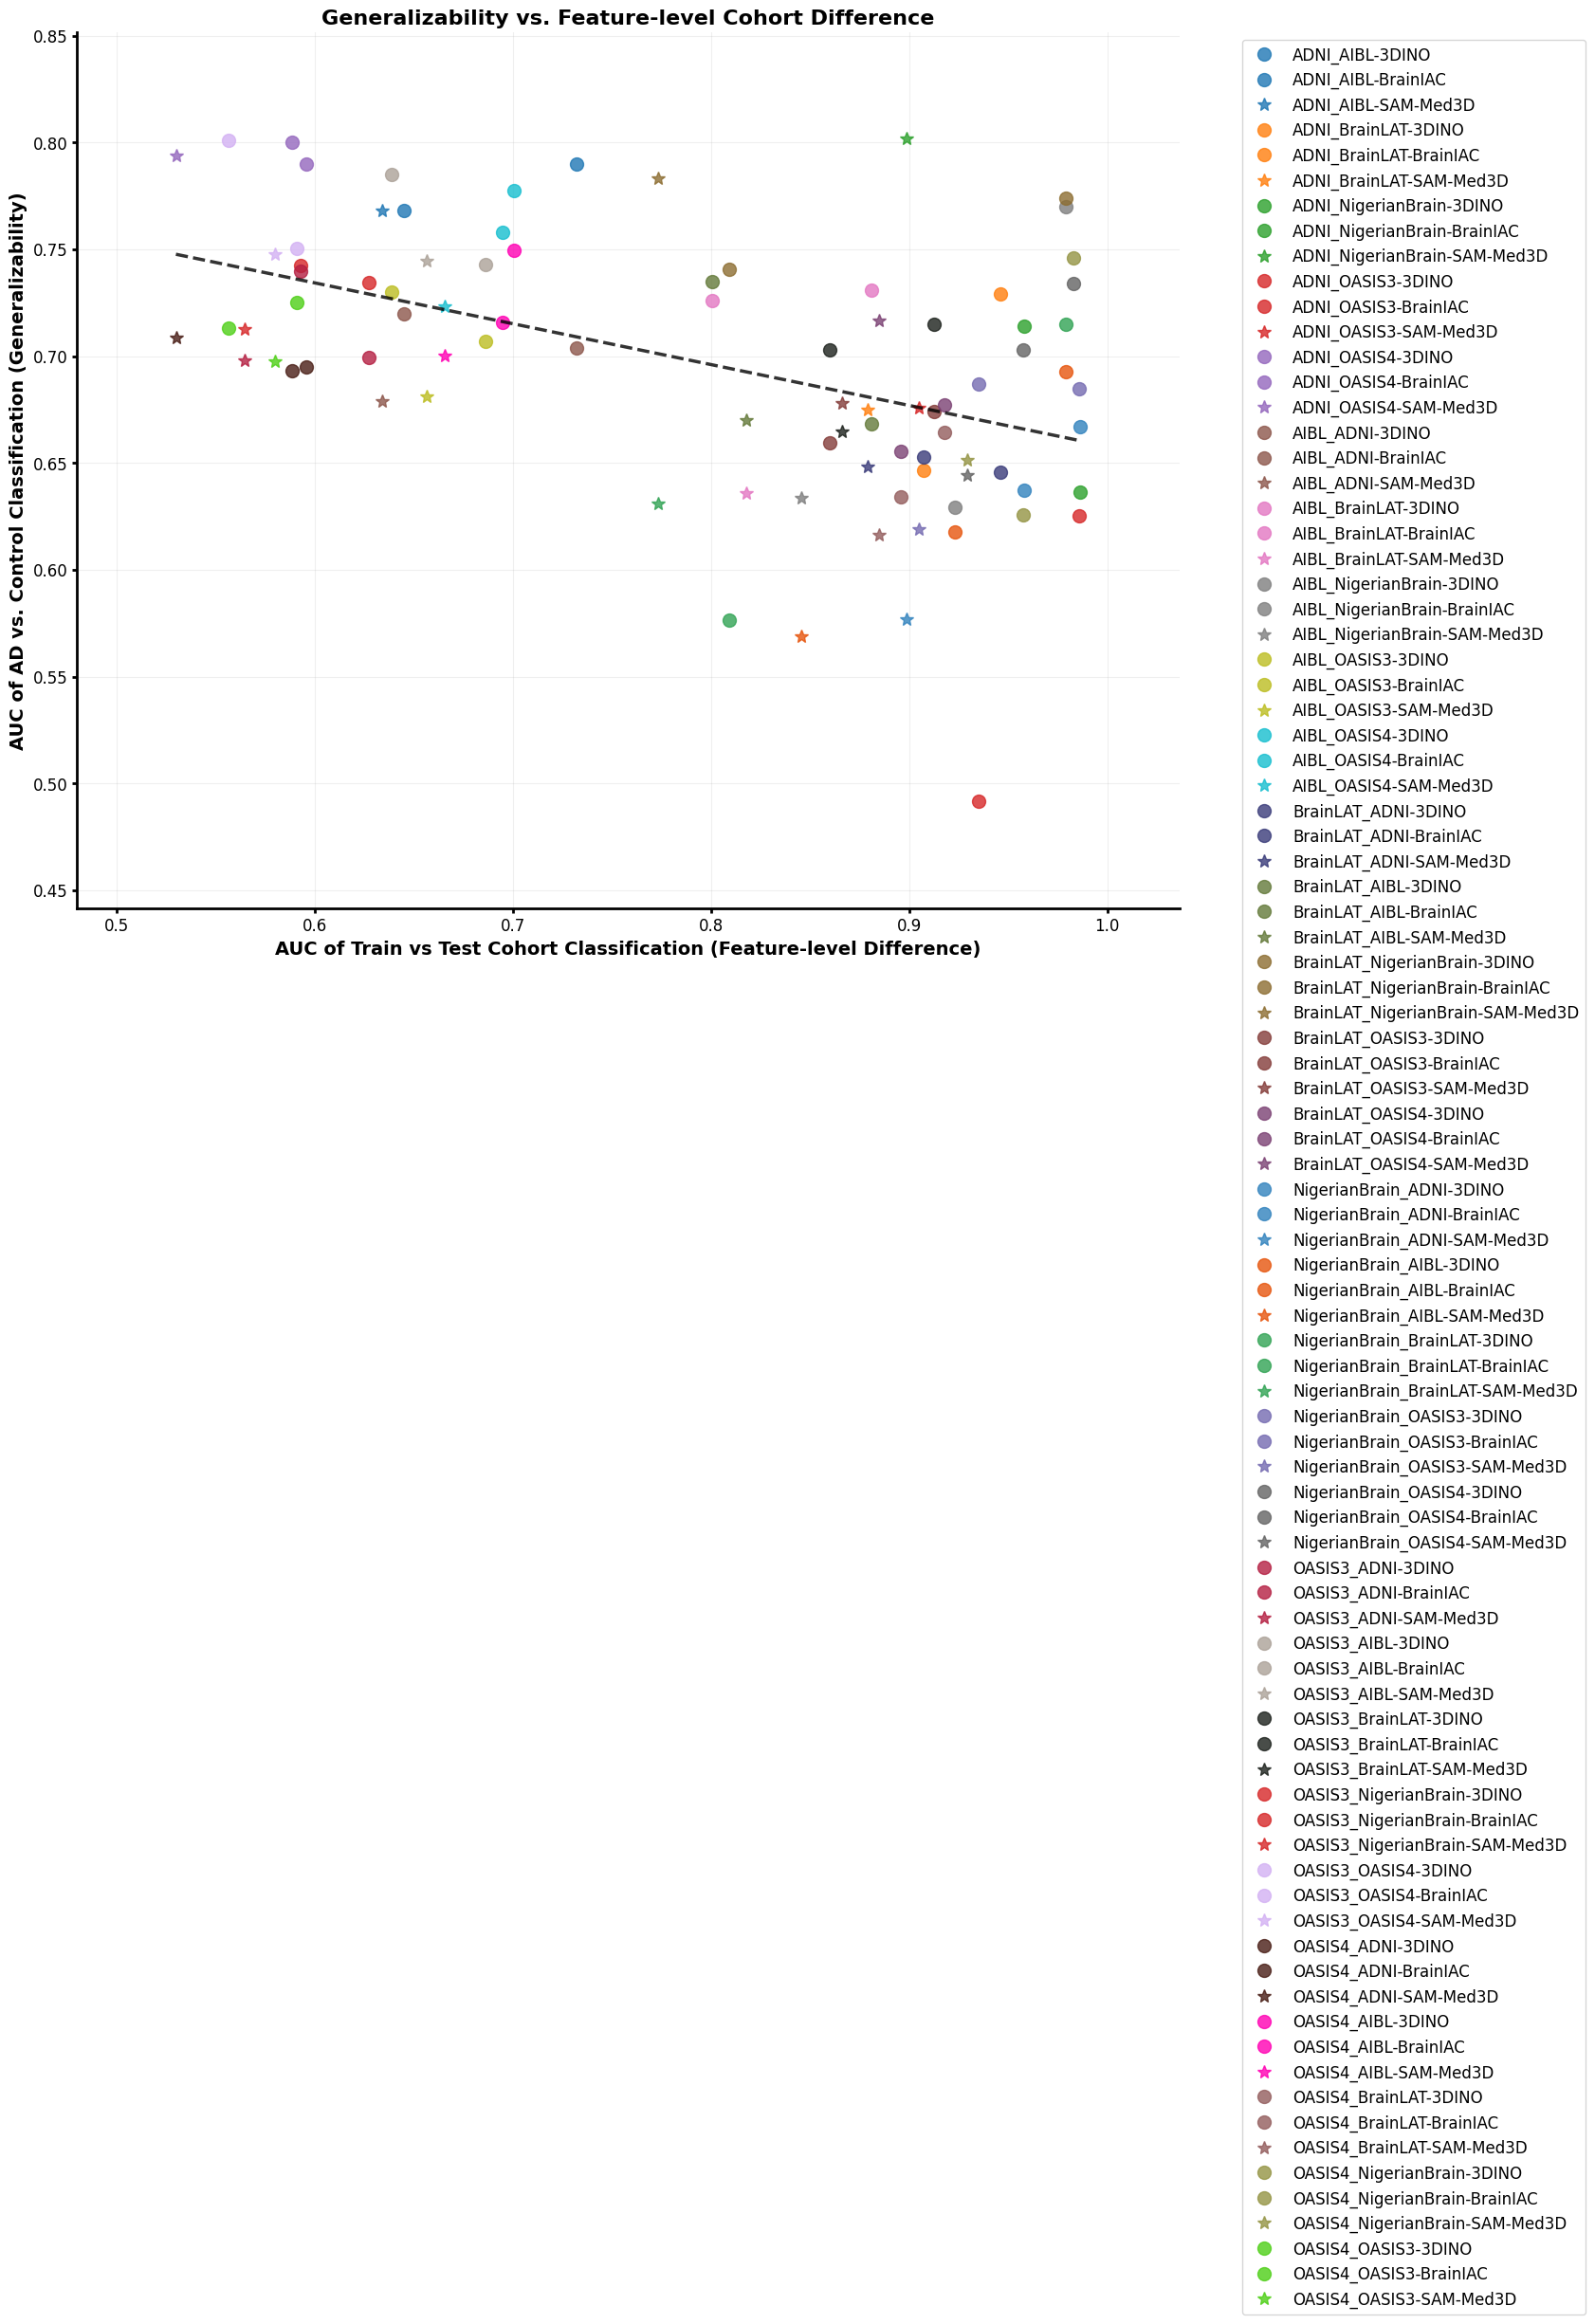

Spearman's ρ (rho): -0.449, p-value: 0.0000
Pearson's r: -0.481, p-value: 0.0000


In [56]:
# Example exp_names (for context)

exp_names = combined_df['experiment'].tolist()

# Define colors for each dataset prefix
dataset_names = sorted(set([name.split('-')[0] for name in exp_names]))
color_map = dict(zip(dataset_names,  [
    "#1f77b4",  # Blue
    "#ff7f0e",  # Orange
    "#2ca02c",  # Green
    "#d62728",  # Red
    "#9467bd",  # Purple
    "#8c564b",  # Brown
    "#e377c2",  # Pink
    "#7f7f7f",  # Gray
    "#bcbd22",  # Olive
    "#17becf",  # Teal
    "#393b79",  # Dark Blue
    "#637939",  # Dark Green
    "#8c6d31",  # Dark Brown
    "#843c39",  # Dark Red
    "#7b4173",  # Violet
    "#3182bd",  # Light Blue
    "#e6550d",  # Deep Orange
    "#31a354",  # Bright Green
    "#756bb1",  # Medium Purple
    "#636363",   # Dark Gray
    "#b41f42",  # Blue
    "#aba198",  # Orange
    "#1b201b",  # Green
    "#d62728",  # Red
    "#d3b1f3",  # Purple
    "#481d15",  # Brown
    "#ff00b3",  # Pink
    "#935d5d",  # Gray
    "#949444",  # Olive
    "#4ecf17"  # Teal
]))

# Assign markers based on suffix
marker_map = {'BrainIAC': 'o', 'SAM-Med3D': '*', 'DINO': 's'}

mean_cohort_acc = combined_df['cohort_mean'].values
mean_adcn_acc = combined_df['disease_mean'].values
std_cohort_acc = combined_df['cohort_std'].values
std_adcn_acc = combined_df['disease_std'].values
# Prepare plot data with color and marker
plot_data = []
for i, name in enumerate(exp_names):
    dataset_prefix = name.split('-')[0]
    experiment_suffix = '-'.join(name.split('-')[1:])
    color = color_map[dataset_prefix]
    marker = marker_map.get(experiment_suffix, 'o')  # default to circle if unknown
    plot_data.append((name, mean_cohort_acc[i], mean_adcn_acc[i], 
                     std_cohort_acc[i], std_adcn_acc[i], color, marker))

# Sort alphabetically for legend
plot_data.sort(key=lambda x: x[0])

# Create figure
plt.figure(figsize=(15, 12))

# # Plot error bars
# for name, x, y, xerr, yerr, color, marker in plot_data:
#     plt.errorbar(x, y, xerr=xerr, yerr=yerr, fmt='none', color=color,
#                  capsize=5, capthick=2, elinewidth=2, alpha=0.6)

# Plot scatter points
for name, x, y, xerr, yerr, color, marker in plot_data:
    plt.plot(x, y, marker=marker, color=color, markersize=10, alpha=0.8,
             linestyle='none', label=name)

# Linear regression trend line
X = mean_cohort_acc.reshape(-1, 1)
y = mean_adcn_acc
lr_model = LinearRegression()
lr_model.fit(X, y)
x_line = np.linspace(min(mean_cohort_acc), max(mean_cohort_acc), 100).reshape(-1, 1)
y_line = lr_model.predict(x_line)
plt.plot(x_line, y_line, color='black', linestyle='--', linewidth=2.5, alpha=0.8,
         label='_nolegend_')  # prevents trendline from appearing in legend

# Labels and title
plt.xlabel('AUC of Train vs Test Cohort Classification (Feature-level Difference)', fontsize=14, fontweight='bold')
plt.ylabel('AUC of AD vs. Control Classification (Generalizability)', fontsize=14, fontweight='bold')
plt.title('Generalizability vs. Feature-level Cohort Difference', fontsize=16, fontweight='bold')

# Axes formatting
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_linewidth(2)
ax.tick_params(width=2, labelsize=12)

ax = plt.gca()
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.2f'))

# Grid
plt.grid(True, alpha=0.2, linestyle='-')

# Axis limits with padding
plt.xlim(min(mean_cohort_acc) - 0.05, max(mean_cohort_acc) + 0.05)
plt.ylim(min(mean_adcn_acc) - 0.05, max(mean_adcn_acc) + 0.05)

# Legend below plot, alphabetical order
handles, labels = ax.get_legend_handles_labels()
sorted_handles_labels = sorted(zip(labels, handles), key=lambda x: x[0])
labels_sorted, handles_sorted = zip(*sorted_handles_labels)
plt.legend(handles_sorted, labels_sorted, bbox_to_anchor=(1.05, 1), loc='upper left',
           fontsize=12)

plt.tight_layout()
plt.show()

# Spearman correlation
rho, p_value = stats.spearmanr(mean_cohort_acc, mean_adcn_acc)
print(f"Spearman's ρ (rho): {rho:.3f}, p-value: {p_value:.4f}")

# Pearson correlation
pearson_r, pearson_p = stats.pearsonr(mean_cohort_acc, mean_adcn_acc)
print(f"Pearson's r: {pearson_r:.3f}, p-value: {pearson_p:.4f}")


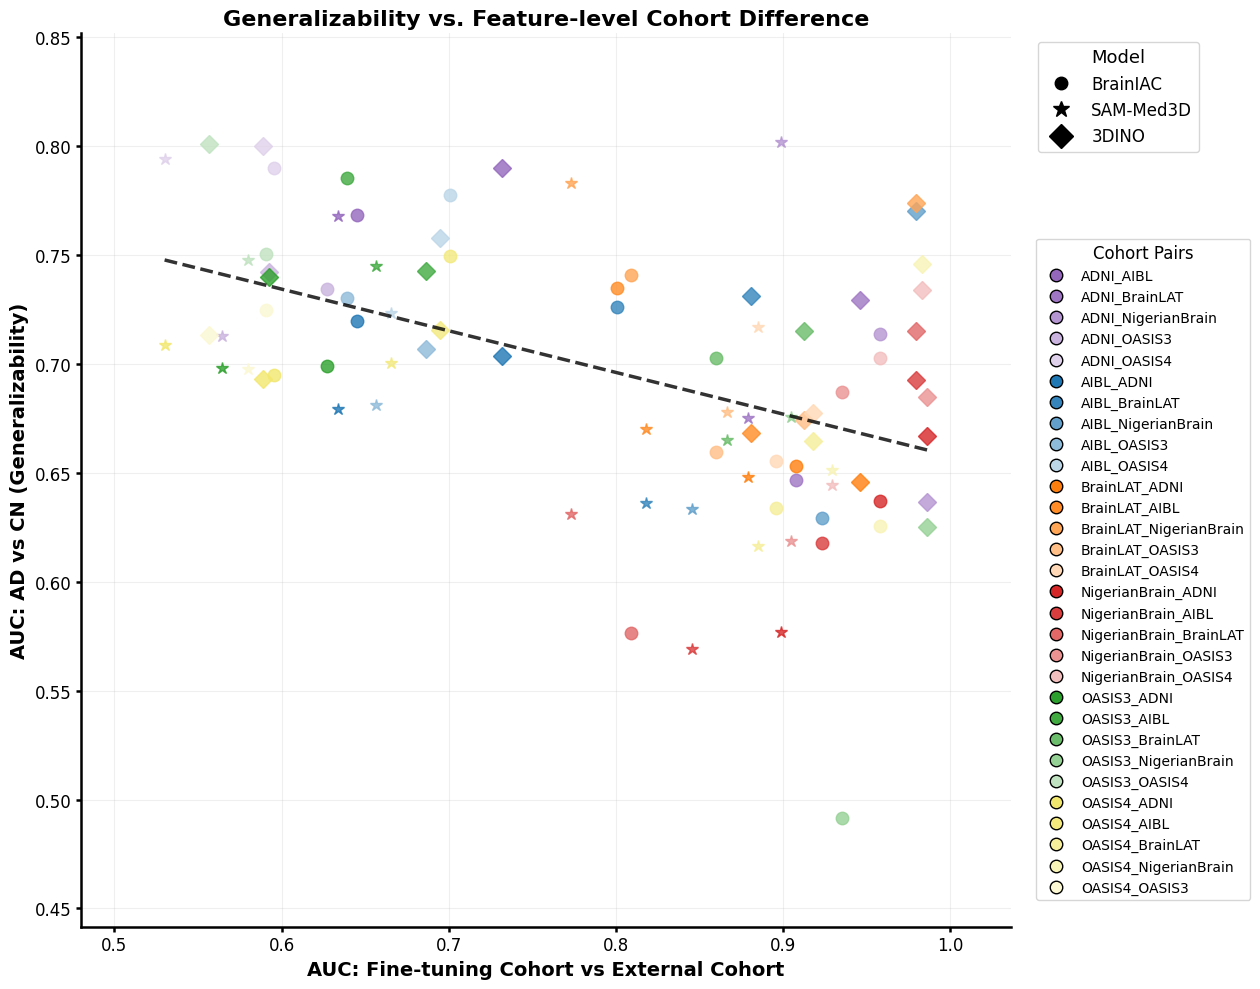

In [60]:
# -------------------------------
# Model markers
# -------------------------------
marker_map = {'BrainIAC': 'o', 'SAM-Med3D': '*', '3DINO': 'D'}

# -------------------------------
# Base colors per fine-tuning cohort
# -------------------------------
base_colors = {
    "AIBL": "#1f77b4",        # blue
    "BrainLAT": "#ff7f0e",    # orange
    "OASIS3": "#2ca02c",       # green
    "OASIS4": "#f2e76e",       # yellow
    "NigerianBrain": "#d62728",  # red
    "ADNI": "#9467bd"         # purple
}

# -------------------------------
# Generate 4 shades per fine-tuning cohort
# -------------------------------
def lighten_color(color, amount=0.5):
    c = np.array(mcolors.to_rgb(color))
    white = np.array([1,1,1])
    return tuple(c + (white - c) * amount)

shades_per_cohort = {}
for cohort, base in base_colors.items():
    shades = [base]  # original
    for amt in [0.1, 0.3, 0.5, 0.7]:  # lighter shades
        shades.append(mcolors.to_hex(lighten_color(base, amt)))
    shades_per_cohort[cohort] = shades

# -------------------------------
# Assign a color per fine-tuning → testing cohort pair
# -------------------------------
pair_color_map = {}
# Determine all unique testing cohorts per fine-tuning
ft_to_tests = {}
for name in exp_names:
    pair = name.split('-')[0]
    ft = pair.split('_')[0]
    test = pair.split('_')[1]
    if ft not in ft_to_tests:
        ft_to_tests[ft] = []
    if test not in ft_to_tests[ft]:
        ft_to_tests[ft].append(test)

# Map 4 shades to 4 testing cohorts
for ft, tests in ft_to_tests.items():
    for i, test in enumerate(sorted(tests)):
        pair = f"{ft}_{test}"
        pair_color_map[pair] = shades_per_cohort[ft][i]

# -------------------------------
# Prepare plot data
# -------------------------------
plot_data = []
for i, name in enumerate(exp_names):
    pair = name.split('-')[0]
    model = '-'.join(name.split('-')[1:])
    color = pair_color_map[pair]
    marker = marker_map.get(model)
    plot_data.append((pair, mean_cohort_acc[i], mean_adcn_acc[i],
                      std_cohort_acc[i], std_adcn_acc[i], color, marker))

plot_data.sort(key=lambda x: x[0])

# -------------------------------
# Create figure
# -------------------------------
plt.figure(figsize=(15, 10))
ax = plt.gca()

# Without Error bars
for pair, x, y, xerr, yerr, color, marker in plot_data:
    ax.errorbar(x, y, fmt='none', color=color,
                capsize=4, capthick=1.5, elinewidth=1.5, alpha=0.5)

# Scatter points
for pair, x, y, xerr, yerr, color, marker in plot_data:
    ax.plot(x, y, marker=marker, color=color, markersize=9, alpha=0.8,
            linestyle='none')

# # Plot error bars
# for name, x, y, xerr, yerr, color, marker in plot_data:
#     plt.errorbar(x, y, xerr=xerr, yerr=yerr, fmt='none', color=color,
#                  capsize=5, capthick=2, elinewidth=2, alpha=0.6)

# # Plot scatter points
# for name, x, y, xerr, yerr, color, marker in plot_data:
#     plt.plot(x, y, marker=marker, color=color, markersize=10, alpha=0.8,
#              linestyle='none', label=name)

# Linear regression
X = mean_cohort_acc.reshape(-1, 1)
y = mean_adcn_acc
lr_model = LinearRegression().fit(X, y)
x_line = np.linspace(min(mean_cohort_acc), max(mean_cohort_acc), 100).reshape(-1, 1)
y_line = lr_model.predict(x_line)
ax.plot(x_line, y_line, color='black', linestyle='--', linewidth=2.5, alpha=0.8,
        label='_nolegend_')

# Labels
ax.set_xlabel('AUC: Fine-tuning Cohort vs External Cohort', fontsize=14, fontweight='bold')
ax.set_ylabel('AUC: AD vs CN (Generalizability)', fontsize=14, fontweight='bold')
ax.set_title('Generalizability vs. Feature-level Cohort Difference', fontsize=16, fontweight='bold')

# Axes styling
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(1.8)
ax.spines['left'].set_linewidth(1.8)
ax.tick_params(width=1.8, labelsize=12)
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.2f'))

# Grid
ax.grid(True, alpha=0.2, linestyle='-')

# Axis limits
ax.set_xlim(min(mean_cohort_acc)-0.05, max(mean_cohort_acc)+0.05)
ax.set_ylim(min(mean_adcn_acc)-0.05, max(mean_adcn_acc)+0.05)

# -------------------------------
# Marker legend (model type)
# -------------------------------
marker_handles = [
    Line2D([0],[0], marker='o', color='black', linestyle='none', markersize=9, label='BrainIAC'),
    Line2D([0],[0], marker='*', color='black', linestyle='none', markersize=12, label='SAM-Med3D'),
    Line2D([0],[0], marker='D', color='black', linestyle='none', markersize=12, label='3DINO')
]
legend1 = ax.legend(handles=marker_handles, title='Model', loc='upper left',
                    bbox_to_anchor=(1.02, 1), fontsize=12, title_fontsize=13)
ax.add_artist(legend1)

# -------------------------------
# Legend for cohort pairs (20 lines)
# -------------------------------
legend_handles = []
seen_pairs = set()
for pair, x, y, xerr, yerr, color, marker in plot_data:
    if pair not in seen_pairs:
        handle = Line2D([0], [0], marker='o', color='black',
                        markerfacecolor=color, linestyle='none', markersize=9, label=pair)
        legend_handles.append(handle)
        seen_pairs.add(pair)

legend2 = ax.legend(handles=legend_handles, title='Cohort Pairs',
                    loc='center left', bbox_to_anchor=(1.02, 0.4),
                    fontsize=10, title_fontsize=12)

# Tight layout
plt.tight_layout(rect=[0,0,0.85,1])
plt.show()


# Balanced Accuracy

In [93]:
metric_col = 'balanced_accuracy'

In [94]:
cohort_summary = (
    df_cohort_all
    .groupby(["experiment", "model"])[metric_col]
    .agg(cohort_mean="mean", cohort_std="std")
    .reset_index()
)
cohort_summary["cohort_pair"] = (
    cohort_summary["experiment"]
    .str.split("_")
    .apply(lambda x: tuple(sorted(x)))
)


In [95]:
cohort_summary

,experiment,model,cohort_mean,cohort_std,cohort_pair
0,ADNI_AIBL,3DINO,0.669000,0.053608,"(ADNI, AIBL)"
1,ADNI_AIBL,BrainIAC,0.598667,0.036808,"(ADNI, AIBL)"
2,ADNI_AIBL,SAM-Med3D,0.602333,0.038890,"(ADNI, AIBL)"
3,ADNI_BrainLAT,3DINO,0.879000,0.019738,"(ADNI, BrainLAT)"
4,ADNI_BrainLAT,BrainIAC,0.828333,0.035664,"(ADNI, BrainLAT)"
5,ADNI_BrainLAT,SAM-Med3D,0.793667,0.030395,"(ADNI, BrainLAT)"
6,ADNI_NigerianBrain,3DINO,0.944310,0.042693,"(ADNI, NigerianBrain)"
7,ADNI_NigerianBrain,BrainIAC,0.906643,0.046945,"(ADNI, NigerianBrain)"
8,ADNI_NigerianBrain,SAM-Med3D,0.732929,0.091757,"(ADNI, NigerianBrain)"
9,ADNI_OASIS3,3DINO,0.557000,0.037555,"(ADNI, OASIS3)"


In [96]:
disease_summary = (
    df_disease_all
    .groupby(["train", "test", "model"])[metric_col]
    .agg(disease_mean="mean", disease_std="std")
    .reset_index()
)

disease_summary["cohort_pair"] = (
    disease_summary[["train", "test"]]
    .apply(lambda r: tuple(sorted(r)), axis=1)
)
disease_summary

,train,test,model,disease_mean,disease_std,cohort_pair
0,ADNI,AIBL,3DINO,0.726223,0.021116,"(ADNI, AIBL)"
1,ADNI,AIBL,BrainIAC,0.704323,0.025283,"(ADNI, AIBL)"
2,ADNI,AIBL,SAM-Med3D,0.701120,0.048466,"(ADNI, AIBL)"
3,ADNI,BrainLAT,3DINO,0.657923,0.017047,"(ADNI, BrainLAT)"
4,ADNI,BrainLAT,BrainIAC,0.595695,0.030345,"(ADNI, BrainLAT)"
...,...,...,...,...,...,...
85,OASIS4,NigerianBrain,BrainIAC,0.581602,0.086650,"(NigerianBrain, OASIS4)"
86,OASIS4,NigerianBrain,SAM-Med3D,0.598108,0.060980,"(NigerianBrain, OASIS4)"
87,OASIS4,OASIS3,3DINO,0.635554,0.027171,"(OASIS3, OASIS4)"
88,OASIS4,OASIS3,BrainIAC,0.623614,0.027734,"(OASIS3, OASIS4)"


In [97]:
def add_cohort_pair(df):
    df = df.copy()
    df["cohort_pair"] = (
        df["experiment"]
        .str.split("_")
        .apply(lambda x: "_".join(sorted(x)))
    )
    return df

In [98]:
cohort_summary["cohort_pair"] = (
    cohort_summary["experiment"]
    .str.split("_")
    .apply(lambda x: tuple(sorted(x)))
)
disease_summary["cohort_pair"] = (
    disease_summary[["train", "test"]]
    .apply(lambda r: tuple(sorted(r)), axis=1)
)

In [99]:
combined_df = (
    disease_summary
    .merge(
        cohort_summary[["cohort_pair", "model", "cohort_mean", "cohort_std"]],
        on=["cohort_pair", "model"],
        how="inner"
    )
)

In [100]:
combined_df["cohort_pair"] = combined_df["cohort_pair"].apply(lambda x: "_".join(x))

In [101]:
combined_df['model'].value_counts()

model
3DINO        30
BrainIAC     30
SAM-Med3D    30
Name: count, dtype: int64

In [ ]:
# combined_df = combined_df[~(combined_df['train'] == 'OASIS3')]
# combined_df = combined_df[~(combined_df['test'] == 'OASIS3')]

In [102]:
combined_df['experiment'] = combined_df['train'] + '_' + combined_df['test'] + '-' + combined_df['model']

In [103]:
combined_df['train_size'] = combined_df['train'].map(sizes_dict)
combined_df['test_size'] = combined_df['test'].map(sizes_dict)

In [104]:
rho, p_value = stats.spearmanr(combined_df['cohort_mean'], combined_df['disease_mean'])
rho, p_value

(-0.5048801156913312, 3.8858482824502815e-07)

In [105]:
combined_df['model'].value_counts()

model
3DINO        30
BrainIAC     30
SAM-Med3D    30
Name: count, dtype: int64

In [106]:
stats_r = importr('stats')
# convert to R dataframe
with localconverter(pandas2ri.converter):
    r_df = pandas2ri.py2rpy(combined_df)

In [107]:
# ----- ANOVA: disease_mean ~ cohort_mean -----
anova1 = stats_r.aov(r('disease_mean ~ cohort_mean'), data=r_df)
print(r['summary'](anova1))

R callback write-console: In addition:   
R callback write-console: Warning message:
  
R callback write-console: In (function (package, help, pos = 2, lib.loc = NULL, character.only = FALSE,  :  
R callback write-console: 
   
R callback write-console:  library ‘/usr/lib/R/site-library’ contains no packages
  


            Df  Sum Sq Mean Sq F value   Pr(>F)    
cohort_mean  1 0.05731 0.05731   31.18 2.57e-07 ***
Residuals   88 0.16172 0.00184                     
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1



In [ ]:
# ----- ANOVA: disease_mean ~ cohort_mean + model -----
anova2 = stats_r.aov(r('disease_mean ~ cohort_mean + model'), data=r_df)
print(r['summary'](anova2))

            Df  Sum Sq Mean Sq F value   Pr(>F)    
cohort_mean  1 0.07159 0.07159  29.729 4.68e-07 ***
model        2 0.03033 0.01516   6.297   0.0028 ** 
Residuals   86 0.20710 0.00241                     
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1



In [108]:
anova3 = stats_r.aov(r('disease_mean ~ cohort_mean + model + train_size + test_size'), data=r_df)
print(r['summary'](anova3))

            Df  Sum Sq Mean Sq F value   Pr(>F)    
cohort_mean  1 0.05731 0.05731  36.846 3.56e-08 ***
model        2 0.01979 0.00990   6.363  0.00267 ** 
train_size   1 0.00790 0.00790   5.078  0.02684 *  
test_size    1 0.00338 0.00338   2.175  0.14402    
Residuals   84 0.13065 0.00156                     
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1



/tmp/ipykernel_85921/383407235.py:113: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


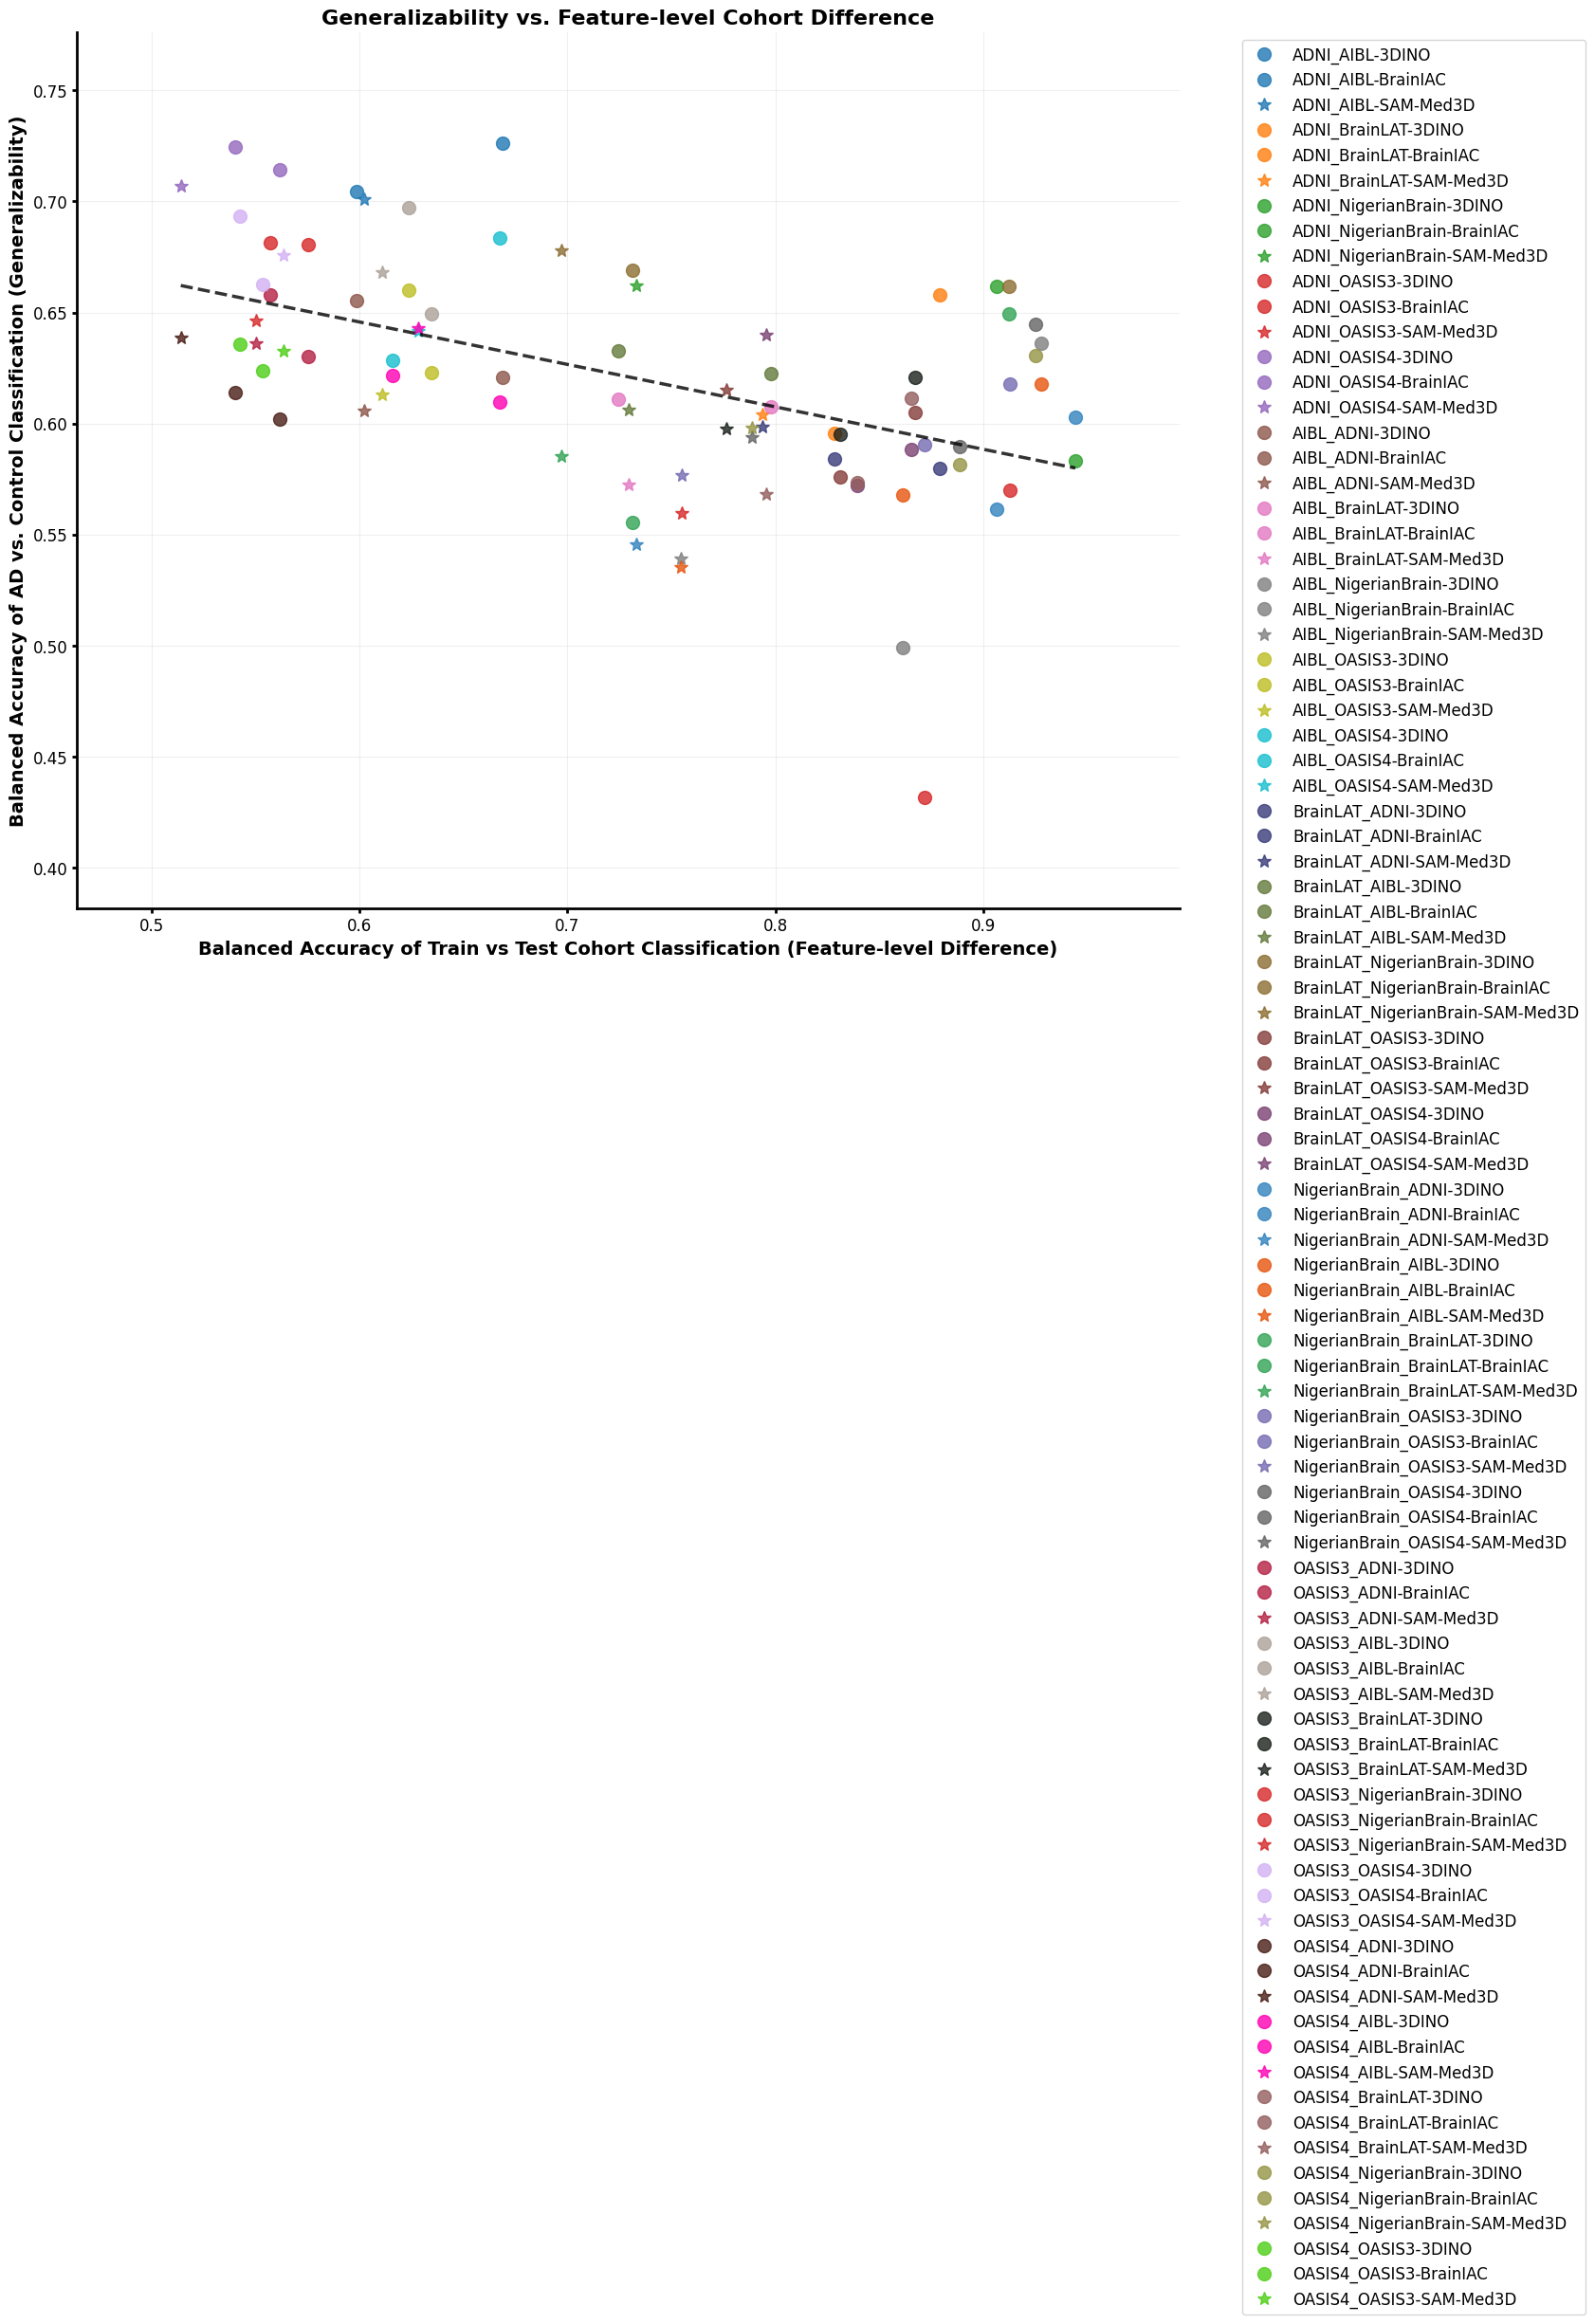

Spearman's ρ (rho): -0.505, p-value: 0.0000
Pearson's r: -0.512, p-value: 0.0000


In [109]:
# Example exp_names (for context)

exp_names = combined_df['experiment'].tolist()

# Define colors for each dataset prefix
dataset_names = sorted(set([name.split('-')[0] for name in exp_names]))
color_map = dict(zip(dataset_names,  [
    "#1f77b4",  # Blue
    "#ff7f0e",  # Orange
    "#2ca02c",  # Green
    "#d62728",  # Red
    "#9467bd",  # Purple
    "#8c564b",  # Brown
    "#e377c2",  # Pink
    "#7f7f7f",  # Gray
    "#bcbd22",  # Olive
    "#17becf",  # Teal
    "#393b79",  # Dark Blue
    "#637939",  # Dark Green
    "#8c6d31",  # Dark Brown
    "#843c39",  # Dark Red
    "#7b4173",  # Violet
    "#3182bd",  # Light Blue
    "#e6550d",  # Deep Orange
    "#31a354",  # Bright Green
    "#756bb1",  # Medium Purple
    "#636363",   # Dark Gray
    "#b41f42",  # Blue
    "#aba198",  # Orange
    "#1b201b",  # Green
    "#d62728",  # Red
    "#d3b1f3",  # Purple
    "#481d15",  # Brown
    "#ff00b3",  # Pink
    "#935d5d",  # Gray
    "#949444",  # Olive
    "#4ecf17"  # Teal
]))

# Assign markers based on suffix
marker_map = {'BrainIAC': 'o', 'SAM-Med3D': '*', 'DINO': 's'}

mean_cohort_acc = combined_df['cohort_mean'].values
mean_adcn_acc = combined_df['disease_mean'].values
std_cohort_acc = combined_df['cohort_std'].values
std_adcn_acc = combined_df['disease_std'].values
# Prepare plot data with color and marker
plot_data = []
for i, name in enumerate(exp_names):
    dataset_prefix = name.split('-')[0]
    experiment_suffix = '-'.join(name.split('-')[1:])
    color = color_map[dataset_prefix]
    marker = marker_map.get(experiment_suffix, 'o')  # default to circle if unknown
    plot_data.append((name, mean_cohort_acc[i], mean_adcn_acc[i], 
                     std_cohort_acc[i], std_adcn_acc[i], color, marker))

# Sort alphabetically for legend
plot_data.sort(key=lambda x: x[0])

# Create figure
plt.figure(figsize=(15, 12))

# # Plot error bars
# for name, x, y, xerr, yerr, color, marker in plot_data:
#     plt.errorbar(x, y, xerr=xerr, yerr=yerr, fmt='none', color=color,
#                  capsize=5, capthick=2, elinewidth=2, alpha=0.6)

# Plot scatter points
for name, x, y, xerr, yerr, color, marker in plot_data:
    plt.plot(x, y, marker=marker, color=color, markersize=10, alpha=0.8,
             linestyle='none', label=name)

# Linear regression trend line
X = mean_cohort_acc.reshape(-1, 1)
y = mean_adcn_acc
lr_model = LinearRegression()
lr_model.fit(X, y)
x_line = np.linspace(min(mean_cohort_acc), max(mean_cohort_acc), 100).reshape(-1, 1)
y_line = lr_model.predict(x_line)
plt.plot(x_line, y_line, color='black', linestyle='--', linewidth=2.5, alpha=0.8,
         label='_nolegend_')  # prevents trendline from appearing in legend

# Labels and title
plt.xlabel('Balanced Accuracy of Train vs Test Cohort Classification (Feature-level Difference)', fontsize=14, fontweight='bold')
plt.ylabel('Balanced Accuracy of AD vs. Control Classification (Generalizability)', fontsize=14, fontweight='bold')
plt.title('Generalizability vs. Feature-level Cohort Difference', fontsize=16, fontweight='bold')

# Axes formatting
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_linewidth(2)
ax.tick_params(width=2, labelsize=12)

ax = plt.gca()
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.2f'))

# Grid
plt.grid(True, alpha=0.2, linestyle='-')

# Axis limits with padding
plt.xlim(min(mean_cohort_acc) - 0.05, max(mean_cohort_acc) + 0.05)
plt.ylim(min(mean_adcn_acc) - 0.05, max(mean_adcn_acc) + 0.05)

# Legend below plot, alphabetical order
handles, labels = ax.get_legend_handles_labels()
sorted_handles_labels = sorted(zip(labels, handles), key=lambda x: x[0])
labels_sorted, handles_sorted = zip(*sorted_handles_labels)
plt.legend(handles_sorted, labels_sorted, bbox_to_anchor=(1.05, 1), loc='upper left',
           fontsize=12)

plt.tight_layout()
plt.show()

# Spearman correlation
rho, p_value = stats.spearmanr(mean_cohort_acc, mean_adcn_acc)
print(f"Spearman's ρ (rho): {rho:.3f}, p-value: {p_value:.4f}")

# Pearson correlation
pearson_r, pearson_p = stats.pearsonr(mean_cohort_acc, mean_adcn_acc)
print(f"Pearson's r: {pearson_r:.3f}, p-value: {pearson_p:.4f}")


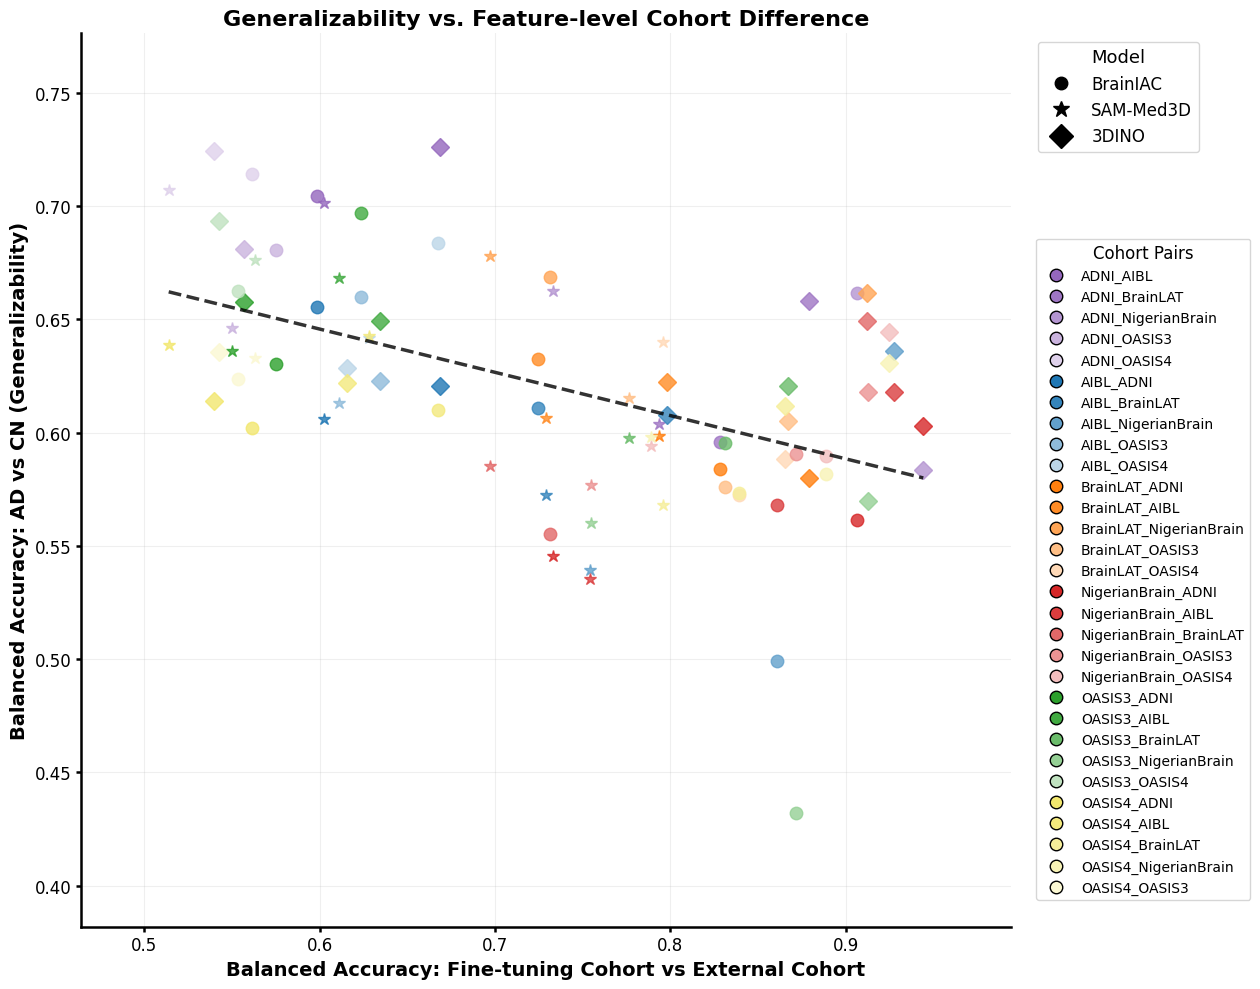

In [111]:
# -------------------------------
# Model markers
# -------------------------------
marker_map = {'BrainIAC': 'o', 'SAM-Med3D': '*', '3DINO': 'D'}

# -------------------------------
# Base colors per fine-tuning cohort
# -------------------------------
base_colors = {
    "AIBL": "#1f77b4",        # blue
    "BrainLAT": "#ff7f0e",    # orange
    "OASIS3": "#2ca02c",       # green
    "OASIS4": "#f2e76e",       # yellow
    "NigerianBrain": "#d62728",  # red
    "ADNI": "#9467bd"         # purple
}

# -------------------------------
# Generate 4 shades per fine-tuning cohort
# -------------------------------
def lighten_color(color, amount=0.5):
    c = np.array(mcolors.to_rgb(color))
    white = np.array([1,1,1])
    return tuple(c + (white - c) * amount)

shades_per_cohort = {}
for cohort, base in base_colors.items():
    shades = [base]  # original
    for amt in [0.1, 0.3, 0.5, 0.7]:  # lighter shades
        shades.append(mcolors.to_hex(lighten_color(base, amt)))
    shades_per_cohort[cohort] = shades

# -------------------------------
# Assign a color per fine-tuning → testing cohort pair
# -------------------------------
pair_color_map = {}
# Determine all unique testing cohorts per fine-tuning
ft_to_tests = {}
for name in exp_names:
    pair = name.split('-')[0]
    ft = pair.split('_')[0]
    test = pair.split('_')[1]
    if ft not in ft_to_tests:
        ft_to_tests[ft] = []
    if test not in ft_to_tests[ft]:
        ft_to_tests[ft].append(test)

# Map 4 shades to 4 testing cohorts
for ft, tests in ft_to_tests.items():
    for i, test in enumerate(sorted(tests)):
        pair = f"{ft}_{test}"
        pair_color_map[pair] = shades_per_cohort[ft][i]

# -------------------------------
# Prepare plot data
# -------------------------------
plot_data = []
for i, name in enumerate(exp_names):
    pair = name.split('-')[0]
    model = '-'.join(name.split('-')[1:])
    color = pair_color_map[pair]
    marker = marker_map.get(model)
    plot_data.append((pair, mean_cohort_acc[i], mean_adcn_acc[i],
                      std_cohort_acc[i], std_adcn_acc[i], color, marker))

plot_data.sort(key=lambda x: x[0])

# -------------------------------
# Create figure
# -------------------------------
plt.figure(figsize=(15, 10))
ax = plt.gca()

# Without Error bars
for pair, x, y, xerr, yerr, color, marker in plot_data:
    ax.errorbar(x, y, fmt='none', color=color,
                capsize=4, capthick=1.5, elinewidth=1.5, alpha=0.5)

# Scatter points
for pair, x, y, xerr, yerr, color, marker in plot_data:
    ax.plot(x, y, marker=marker, color=color, markersize=9, alpha=0.8,
            linestyle='none')

# # Plot error bars
# for name, x, y, xerr, yerr, color, marker in plot_data:
#     plt.errorbar(x, y, xerr=xerr, yerr=yerr, fmt='none', color=color,
#                  capsize=5, capthick=2, elinewidth=2, alpha=0.6)

# # Plot scatter points
# for name, x, y, xerr, yerr, color, marker in plot_data:
#     plt.plot(x, y, marker=marker, color=color, markersize=10, alpha=0.8,
#              linestyle='none', label=name)

# Linear regression
X = mean_cohort_acc.reshape(-1, 1)
y = mean_adcn_acc
lr_model = LinearRegression().fit(X, y)
x_line = np.linspace(min(mean_cohort_acc), max(mean_cohort_acc), 100).reshape(-1, 1)
y_line = lr_model.predict(x_line)
ax.plot(x_line, y_line, color='black', linestyle='--', linewidth=2.5, alpha=0.8,
        label='_nolegend_')

# Labels
ax.set_xlabel('Balanced Accuracy: Fine-tuning Cohort vs External Cohort', fontsize=14, fontweight='bold')
ax.set_ylabel('Balanced Accuracy: AD vs CN (Generalizability)', fontsize=14, fontweight='bold')
ax.set_title('Generalizability vs. Feature-level Cohort Difference', fontsize=16, fontweight='bold')

# Axes styling
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(1.8)
ax.spines['left'].set_linewidth(1.8)
ax.tick_params(width=1.8, labelsize=12)
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.2f'))

# Grid
ax.grid(True, alpha=0.2, linestyle='-')

# Axis limits
ax.set_xlim(min(mean_cohort_acc)-0.05, max(mean_cohort_acc)+0.05)
ax.set_ylim(min(mean_adcn_acc)-0.05, max(mean_adcn_acc)+0.05)

# -------------------------------
# Marker legend (model type)
# -------------------------------
marker_handles = [
    Line2D([0],[0], marker='o', color='black', linestyle='none', markersize=9, label='BrainIAC'),
    Line2D([0],[0], marker='*', color='black', linestyle='none', markersize=12, label='SAM-Med3D'),
    Line2D([0],[0], marker='D', color='black', linestyle='none', markersize=12, label='3DINO')
]
legend1 = ax.legend(handles=marker_handles, title='Model', loc='upper left',
                    bbox_to_anchor=(1.02, 1), fontsize=12, title_fontsize=13)
ax.add_artist(legend1)

# -------------------------------
# Legend for cohort pairs (20 lines)
# -------------------------------
legend_handles = []
seen_pairs = set()
for pair, x, y, xerr, yerr, color, marker in plot_data:
    if pair not in seen_pairs:
        handle = Line2D([0], [0], marker='o', color='black',
                        markerfacecolor=color, linestyle='none', markersize=9, label=pair)
        legend_handles.append(handle)
        seen_pairs.add(pair)

legend2 = ax.legend(handles=legend_handles, title='Cohort Pairs',
                    loc='center left', bbox_to_anchor=(1.02, 0.4),
                    fontsize=10, title_fontsize=12)

# Tight layout
plt.tight_layout(rect=[0,0,0.85,1])
plt.show()


# F1 Score

In [112]:
metric_col = 'f1_score'

In [113]:
cohort_summary = (
    df_cohort_all
    .groupby(["experiment", "model"])[metric_col]
    .agg(cohort_mean="mean", cohort_std="std")
    .reset_index()
)
cohort_summary["cohort_pair"] = (
    cohort_summary["experiment"]
    .str.split("_")
    .apply(lambda x: tuple(sorted(x)))
)


In [114]:
cohort_summary

,experiment,model,cohort_mean,cohort_std,cohort_pair
0,ADNI_AIBL,3DINO,0.673209,0.057390,"(ADNI, AIBL)"
1,ADNI_AIBL,BrainIAC,0.619573,0.044549,"(ADNI, AIBL)"
2,ADNI_AIBL,SAM-Med3D,0.631737,0.053267,"(ADNI, AIBL)"
3,ADNI_BrainLAT,3DINO,0.880578,0.019612,"(ADNI, BrainLAT)"
4,ADNI_BrainLAT,BrainIAC,0.836273,0.033440,"(ADNI, BrainLAT)"
5,ADNI_BrainLAT,SAM-Med3D,0.814981,0.024054,"(ADNI, BrainLAT)"
6,ADNI_NigerianBrain,3DINO,0.989495,0.008045,"(ADNI, NigerianBrain)"
7,ADNI_NigerianBrain,BrainIAC,0.972023,0.011080,"(ADNI, NigerianBrain)"
8,ADNI_NigerianBrain,SAM-Med3D,0.951921,0.015124,"(ADNI, NigerianBrain)"
9,ADNI_OASIS3,3DINO,0.553024,0.043714,"(ADNI, OASIS3)"


In [115]:
disease_summary = (
    df_disease_all
    .groupby(["train", "test", "model"])[metric_col]
    .agg(disease_mean="mean", disease_std="std")
    .reset_index()
)

disease_summary["cohort_pair"] = (
    disease_summary[["train", "test"]]
    .apply(lambda r: tuple(sorted(r)), axis=1)
)
disease_summary

,train,test,model,disease_mean,disease_std,cohort_pair
0,ADNI,AIBL,3DINO,0.465328,0.034281,"(ADNI, AIBL)"
1,ADNI,AIBL,BrainIAC,0.413106,0.033989,"(ADNI, AIBL)"
2,ADNI,AIBL,SAM-Med3D,0.427233,0.050464,"(ADNI, AIBL)"
3,ADNI,BrainLAT,3DINO,0.620757,0.033984,"(ADNI, BrainLAT)"
4,ADNI,BrainLAT,BrainIAC,0.594875,0.046594,"(ADNI, BrainLAT)"
...,...,...,...,...,...,...
85,OASIS4,NigerianBrain,BrainIAC,0.608686,0.072953,"(NigerianBrain, OASIS4)"
86,OASIS4,NigerianBrain,SAM-Med3D,0.581205,0.094798,"(NigerianBrain, OASIS4)"
87,OASIS4,OASIS3,3DINO,0.435078,0.019808,"(OASIS3, OASIS4)"
88,OASIS4,OASIS3,BrainIAC,0.426236,0.019089,"(OASIS3, OASIS4)"


In [116]:
def add_cohort_pair(df):
    df = df.copy()
    df["cohort_pair"] = (
        df["experiment"]
        .str.split("_")
        .apply(lambda x: "_".join(sorted(x)))
    )
    return df

In [117]:
cohort_summary["cohort_pair"] = (
    cohort_summary["experiment"]
    .str.split("_")
    .apply(lambda x: tuple(sorted(x)))
)
disease_summary["cohort_pair"] = (
    disease_summary[["train", "test"]]
    .apply(lambda r: tuple(sorted(r)), axis=1)
)

In [118]:
combined_df = (
    disease_summary
    .merge(
        cohort_summary[["cohort_pair", "model", "cohort_mean", "cohort_std"]],
        on=["cohort_pair", "model"],
        how="inner"
    )
)

In [119]:
combined_df["cohort_pair"] = combined_df["cohort_pair"].apply(lambda x: "_".join(x))

In [120]:
combined_df['model'].value_counts()

model
3DINO        30
BrainIAC     30
SAM-Med3D    30
Name: count, dtype: int64

In [ ]:
# combined_df = combined_df[~(combined_df['train'] == 'OASIS3')]
# combined_df = combined_df[~(combined_df['test'] == 'OASIS3')]

In [121]:
combined_df['experiment'] = combined_df['train'] + '_' + combined_df['test'] + '-' + combined_df['model']

In [122]:
combined_df['train_size'] = combined_df['train'].map(sizes_dict)
combined_df['test_size'] = combined_df['test'].map(sizes_dict)

In [123]:
rho, p_value = stats.spearmanr(combined_df['cohort_mean'], combined_df['disease_mean'])
rho, p_value

(-0.07785118997419001, 0.46579049098920855)

In [124]:
combined_df['model'].value_counts()

model
3DINO        30
BrainIAC     30
SAM-Med3D    30
Name: count, dtype: int64

In [125]:
stats_r = importr('stats')
# convert to R dataframe
with localconverter(pandas2ri.converter):
    r_df = pandas2ri.py2rpy(combined_df)

In [126]:
# ----- ANOVA: disease_mean ~ cohort_mean -----
anova1 = stats_r.aov(r('disease_mean ~ cohort_mean'), data=r_df)
print(r['summary'](anova1))

R callback write-console: In addition:   
R callback write-console: Warning message:
  
R callback write-console: In (function (package, help, pos = 2, lib.loc = NULL, character.only = FALSE,  :  
R callback write-console: 
   
R callback write-console:  library ‘/usr/lib/R/site-library’ contains no packages
  


            Df Sum Sq Mean Sq F value Pr(>F)
cohort_mean  1  0.024 0.02403   0.939  0.335
Residuals   88  2.252 0.02559               



In [127]:
# ----- ANOVA: disease_mean ~ cohort_mean + model -----
anova2 = stats_r.aov(r('disease_mean ~ cohort_mean + model'), data=r_df)
print(r['summary'](anova2))

            Df Sum Sq Mean Sq F value Pr(>F)
cohort_mean  1 0.0240 0.02403   0.939  0.335
model        2 0.0505 0.02527   0.987  0.377
Residuals   86 2.2010 0.02559               



In [128]:
anova3 = stats_r.aov(r('disease_mean ~ cohort_mean + model + train_size + test_size'), data=r_df)
print(r['summary'](anova3))

            Df Sum Sq Mean Sq F value Pr(>F)  
cohort_mean  1 0.0240 0.02403   0.963 0.3292  
model        2 0.0505 0.02527   1.013 0.3675  
train_size   1 0.0007 0.00074   0.029 0.8641  
test_size    1 0.1044 0.10443   4.186 0.0439 *
Residuals   84 2.0958 0.02495                 
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1



/tmp/ipykernel_85921/1869441639.py:113: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


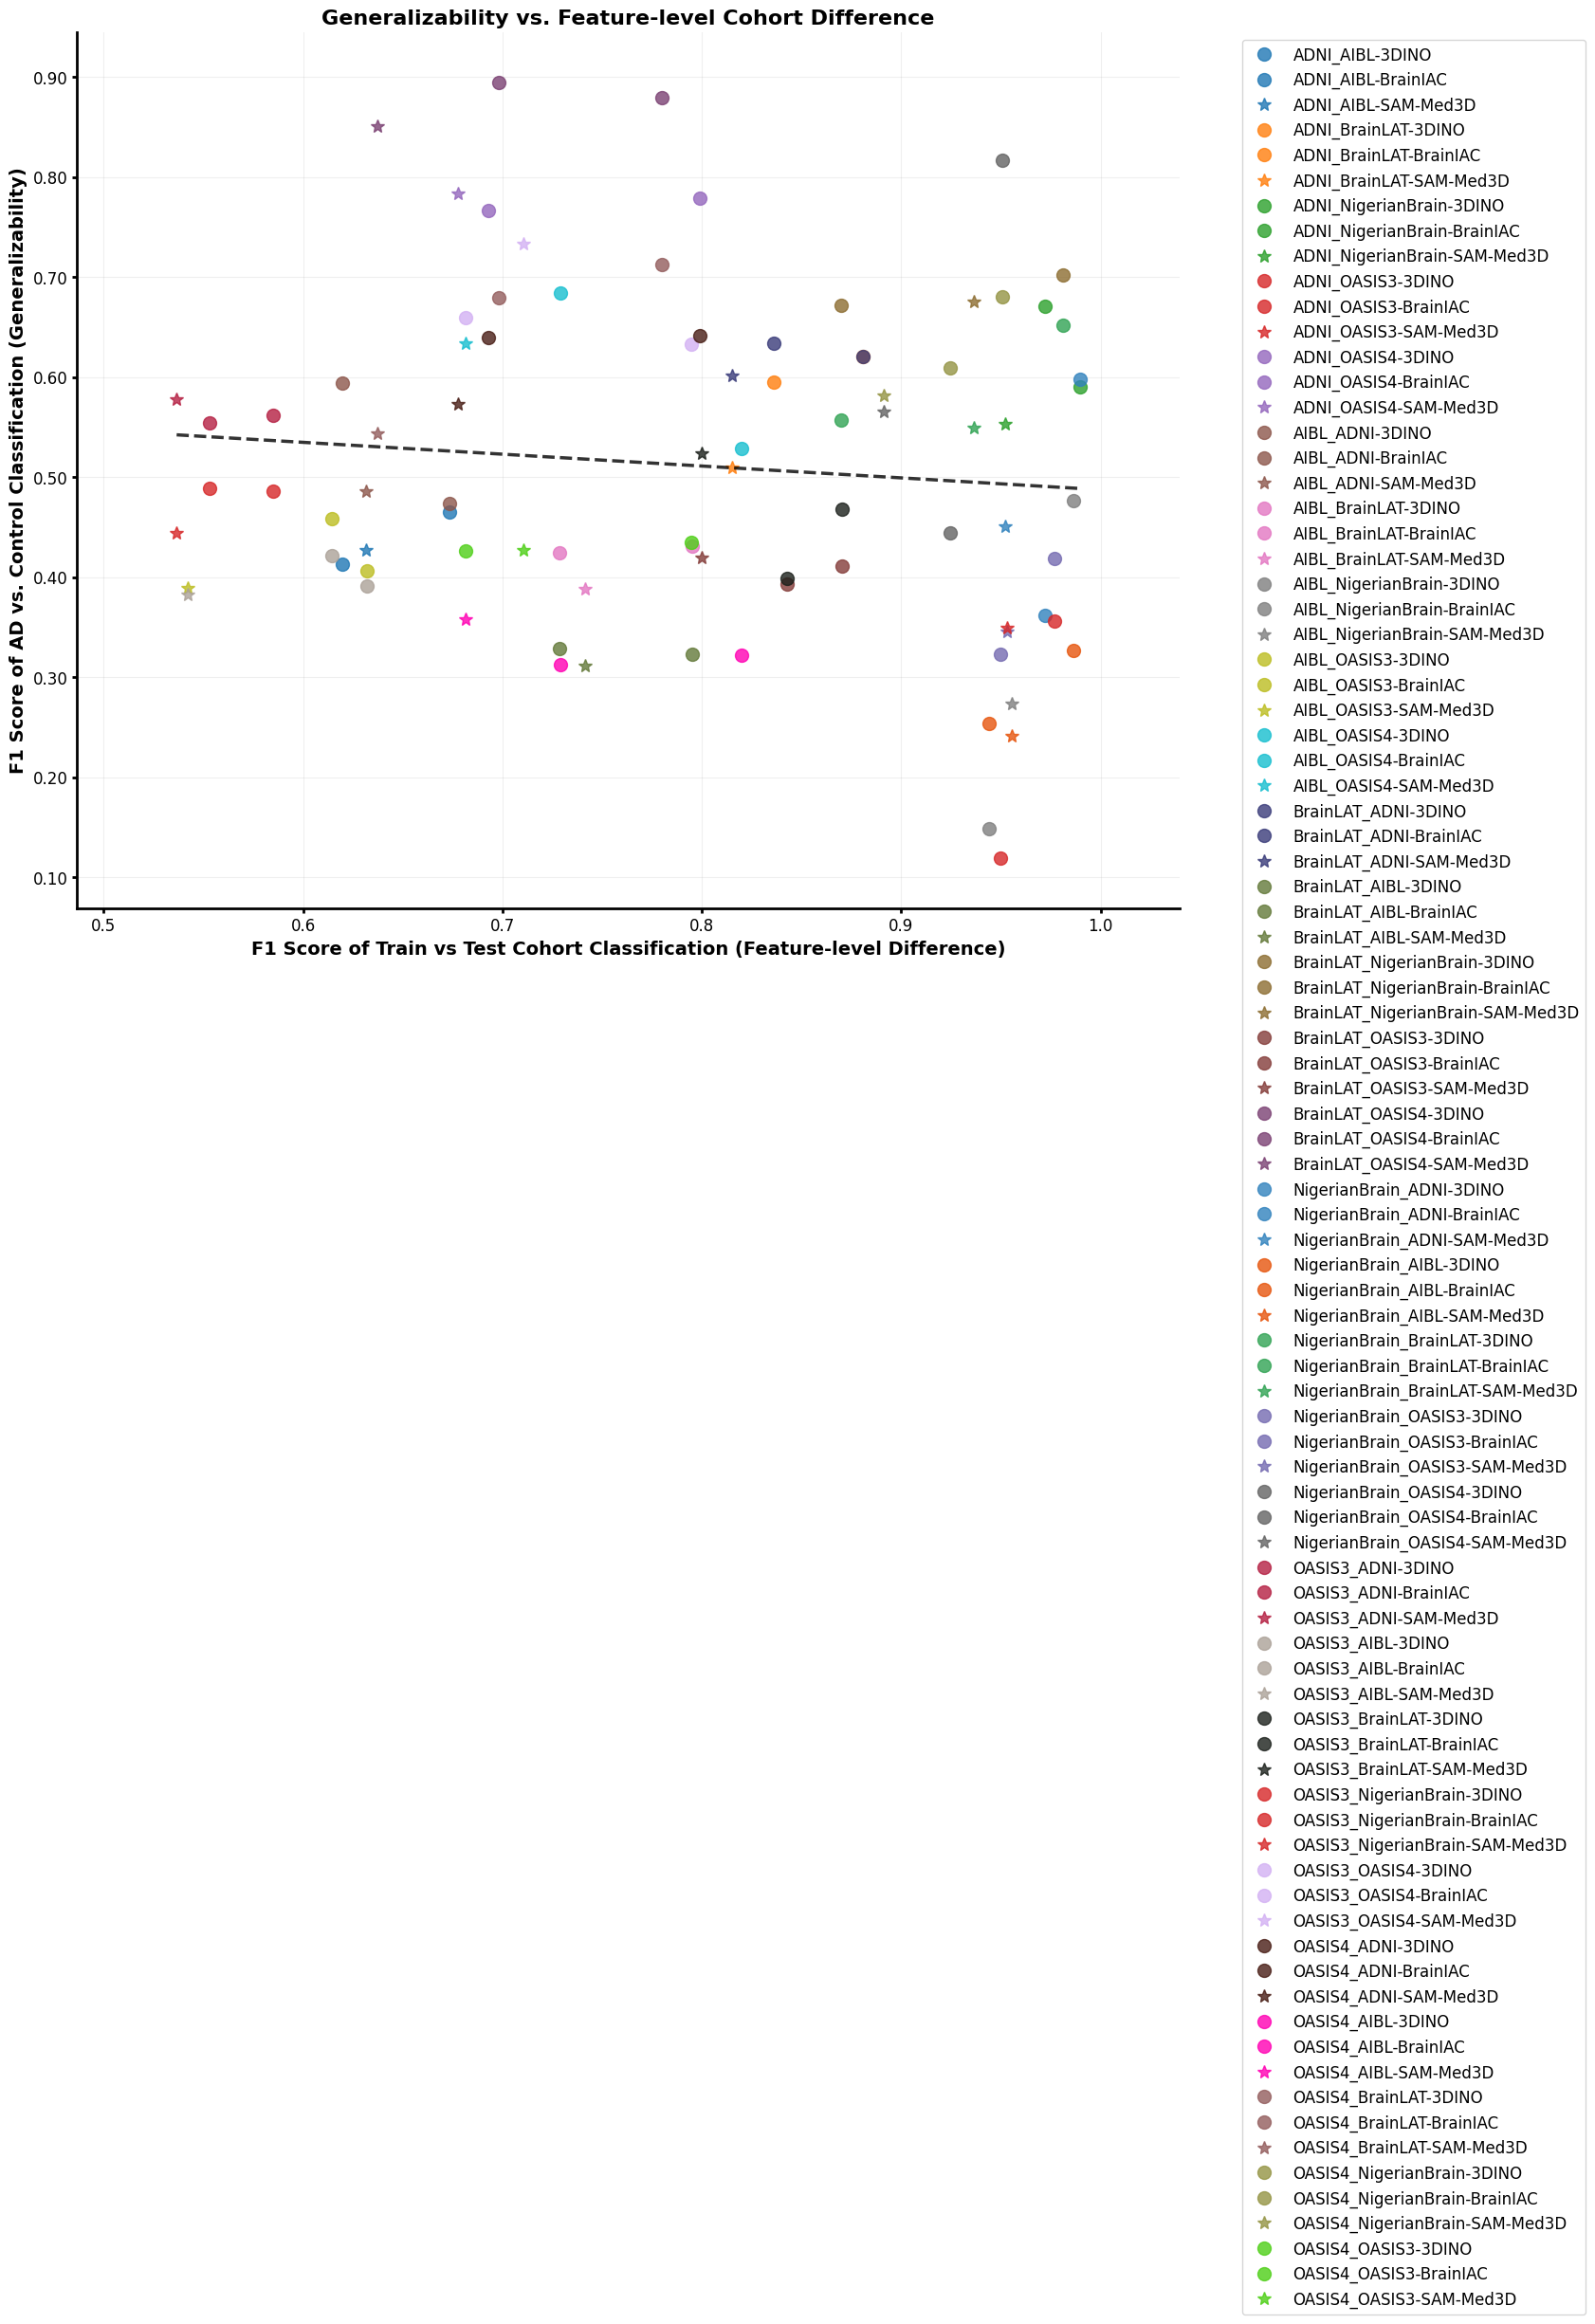

Spearman's ρ (rho): -0.078, p-value: 0.4658
Pearson's r: -0.103, p-value: 0.3352


In [131]:
# Example exp_names (for context)

exp_names = combined_df['experiment'].tolist()

# Define colors for each dataset prefix
dataset_names = sorted(set([name.split('-')[0] for name in exp_names]))
color_map = dict(zip(dataset_names,  [
    "#1f77b4",  # Blue
    "#ff7f0e",  # Orange
    "#2ca02c",  # Green
    "#d62728",  # Red
    "#9467bd",  # Purple
    "#8c564b",  # Brown
    "#e377c2",  # Pink
    "#7f7f7f",  # Gray
    "#bcbd22",  # Olive
    "#17becf",  # Teal
    "#393b79",  # Dark Blue
    "#637939",  # Dark Green
    "#8c6d31",  # Dark Brown
    "#843c39",  # Dark Red
    "#7b4173",  # Violet
    "#3182bd",  # Light Blue
    "#e6550d",  # Deep Orange
    "#31a354",  # Bright Green
    "#756bb1",  # Medium Purple
    "#636363",   # Dark Gray
    "#b41f42",  # Blue
    "#aba198",  # Orange
    "#1b201b",  # Green
    "#d62728",  # Red
    "#d3b1f3",  # Purple
    "#481d15",  # Brown
    "#ff00b3",  # Pink
    "#935d5d",  # Gray
    "#949444",  # Olive
    "#4ecf17"  # Teal
]))

# Assign markers based on suffix
marker_map = {'BrainIAC': 'o', 'SAM-Med3D': '*', 'DINO': 's'}

mean_cohort_acc = combined_df['cohort_mean'].values
mean_adcn_acc = combined_df['disease_mean'].values
std_cohort_acc = combined_df['cohort_std'].values
std_adcn_acc = combined_df['disease_std'].values
# Prepare plot data with color and marker
plot_data = []
for i, name in enumerate(exp_names):
    dataset_prefix = name.split('-')[0]
    experiment_suffix = '-'.join(name.split('-')[1:])
    color = color_map[dataset_prefix]
    marker = marker_map.get(experiment_suffix, 'o')  # default to circle if unknown
    plot_data.append((name, mean_cohort_acc[i], mean_adcn_acc[i], 
                     std_cohort_acc[i], std_adcn_acc[i], color, marker))

# Sort alphabetically for legend
plot_data.sort(key=lambda x: x[0])

# Create figure
plt.figure(figsize=(15, 12))

# # Plot error bars
# for name, x, y, xerr, yerr, color, marker in plot_data:
#     plt.errorbar(x, y, xerr=xerr, yerr=yerr, fmt='none', color=color,
#                  capsize=5, capthick=2, elinewidth=2, alpha=0.6)

# Plot scatter points
for name, x, y, xerr, yerr, color, marker in plot_data:
    plt.plot(x, y, marker=marker, color=color, markersize=10, alpha=0.8,
             linestyle='none', label=name)

# Linear regression trend line
X = mean_cohort_acc.reshape(-1, 1)
y = mean_adcn_acc
lr_model = LinearRegression()
lr_model.fit(X, y)
x_line = np.linspace(min(mean_cohort_acc), max(mean_cohort_acc), 100).reshape(-1, 1)
y_line = lr_model.predict(x_line)
plt.plot(x_line, y_line, color='black', linestyle='--', linewidth=2.5, alpha=0.8,
         label='_nolegend_')  # prevents trendline from appearing in legend

# Labels and title
plt.xlabel('F1 Score of Train vs Test Cohort Classification (Feature-level Difference)', fontsize=14, fontweight='bold')
plt.ylabel('F1 Score of AD vs. Control Classification (Generalizability)', fontsize=14, fontweight='bold')
plt.title('Generalizability vs. Feature-level Cohort Difference', fontsize=16, fontweight='bold')

# Axes formatting
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_linewidth(2)
ax.tick_params(width=2, labelsize=12)

ax = plt.gca()
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.2f'))

# Grid
plt.grid(True, alpha=0.2, linestyle='-')

# Axis limits with padding
plt.xlim(min(mean_cohort_acc) - 0.05, max(mean_cohort_acc) + 0.05)
plt.ylim(min(mean_adcn_acc) - 0.05, max(mean_adcn_acc) + 0.05)

# Legend below plot, alphabetical order
handles, labels = ax.get_legend_handles_labels()
sorted_handles_labels = sorted(zip(labels, handles), key=lambda x: x[0])
labels_sorted, handles_sorted = zip(*sorted_handles_labels)
plt.legend(handles_sorted, labels_sorted, bbox_to_anchor=(1.05, 1), loc='upper left',
           fontsize=12)

plt.tight_layout()
plt.show()

# Spearman correlation
rho, p_value = stats.spearmanr(mean_cohort_acc, mean_adcn_acc)
print(f"Spearman's ρ (rho): {rho:.3f}, p-value: {p_value:.4f}")

# Pearson correlation
pearson_r, pearson_p = stats.pearsonr(mean_cohort_acc, mean_adcn_acc)
print(f"Pearson's r: {pearson_r:.3f}, p-value: {pearson_p:.4f}")


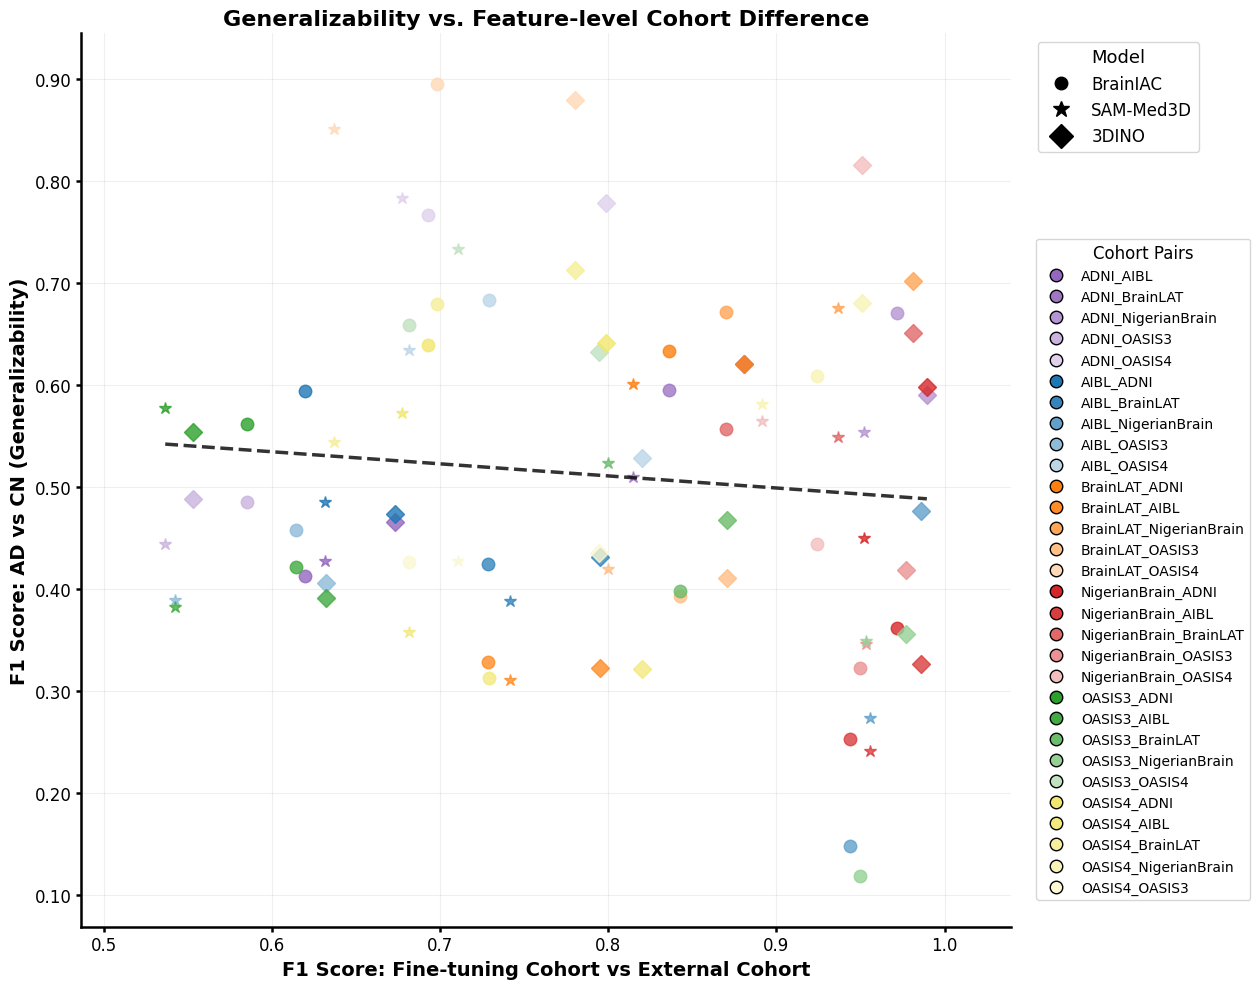

In [132]:
# -------------------------------
# Model markers
# -------------------------------
marker_map = {'BrainIAC': 'o', 'SAM-Med3D': '*', '3DINO': 'D'}

# -------------------------------
# Base colors per fine-tuning cohort
# -------------------------------
base_colors = {
    "AIBL": "#1f77b4",        # blue
    "BrainLAT": "#ff7f0e",    # orange
    "OASIS3": "#2ca02c",       # green
    "OASIS4": "#f2e76e",       # yellow
    "NigerianBrain": "#d62728",  # red
    "ADNI": "#9467bd"         # purple
}

# -------------------------------
# Generate 4 shades per fine-tuning cohort
# -------------------------------
def lighten_color(color, amount=0.5):
    c = np.array(mcolors.to_rgb(color))
    white = np.array([1,1,1])
    return tuple(c + (white - c) * amount)

shades_per_cohort = {}
for cohort, base in base_colors.items():
    shades = [base]  # original
    for amt in [0.1, 0.3, 0.5, 0.7]:  # lighter shades
        shades.append(mcolors.to_hex(lighten_color(base, amt)))
    shades_per_cohort[cohort] = shades

# -------------------------------
# Assign a color per fine-tuning → testing cohort pair
# -------------------------------
pair_color_map = {}
# Determine all unique testing cohorts per fine-tuning
ft_to_tests = {}
for name in exp_names:
    pair = name.split('-')[0]
    ft = pair.split('_')[0]
    test = pair.split('_')[1]
    if ft not in ft_to_tests:
        ft_to_tests[ft] = []
    if test not in ft_to_tests[ft]:
        ft_to_tests[ft].append(test)

# Map 4 shades to 4 testing cohorts
for ft, tests in ft_to_tests.items():
    for i, test in enumerate(sorted(tests)):
        pair = f"{ft}_{test}"
        pair_color_map[pair] = shades_per_cohort[ft][i]

# -------------------------------
# Prepare plot data
# -------------------------------
plot_data = []
for i, name in enumerate(exp_names):
    pair = name.split('-')[0]
    model = '-'.join(name.split('-')[1:])
    color = pair_color_map[pair]
    marker = marker_map.get(model)
    plot_data.append((pair, mean_cohort_acc[i], mean_adcn_acc[i],
                      std_cohort_acc[i], std_adcn_acc[i], color, marker))

plot_data.sort(key=lambda x: x[0])

# -------------------------------
# Create figure
# -------------------------------
plt.figure(figsize=(15, 10))
ax = plt.gca()

# Without Error bars
for pair, x, y, xerr, yerr, color, marker in plot_data:
    ax.errorbar(x, y, fmt='none', color=color,
                capsize=4, capthick=1.5, elinewidth=1.5, alpha=0.5)

# Scatter points
for pair, x, y, xerr, yerr, color, marker in plot_data:
    ax.plot(x, y, marker=marker, color=color, markersize=9, alpha=0.8,
            linestyle='none')

# # Plot error bars
# for name, x, y, xerr, yerr, color, marker in plot_data:
#     plt.errorbar(x, y, xerr=xerr, yerr=yerr, fmt='none', color=color,
#                  capsize=5, capthick=2, elinewidth=2, alpha=0.6)

# # Plot scatter points
# for name, x, y, xerr, yerr, color, marker in plot_data:
#     plt.plot(x, y, marker=marker, color=color, markersize=10, alpha=0.8,
#              linestyle='none', label=name)

# Linear regression
X = mean_cohort_acc.reshape(-1, 1)
y = mean_adcn_acc
lr_model = LinearRegression().fit(X, y)
x_line = np.linspace(min(mean_cohort_acc), max(mean_cohort_acc), 100).reshape(-1, 1)
y_line = lr_model.predict(x_line)
ax.plot(x_line, y_line, color='black', linestyle='--', linewidth=2.5, alpha=0.8,
        label='_nolegend_')

# Labels
ax.set_xlabel('F1 Score: Fine-tuning Cohort vs External Cohort', fontsize=14, fontweight='bold')
ax.set_ylabel('F1 Score: AD vs CN (Generalizability)', fontsize=14, fontweight='bold')
ax.set_title('Generalizability vs. Feature-level Cohort Difference', fontsize=16, fontweight='bold')

# Axes styling
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(1.8)
ax.spines['left'].set_linewidth(1.8)
ax.tick_params(width=1.8, labelsize=12)
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.2f'))

# Grid
ax.grid(True, alpha=0.2, linestyle='-')

# Axis limits
ax.set_xlim(min(mean_cohort_acc)-0.05, max(mean_cohort_acc)+0.05)
ax.set_ylim(min(mean_adcn_acc)-0.05, max(mean_adcn_acc)+0.05)

# -------------------------------
# Marker legend (model type)
# -------------------------------
marker_handles = [
    Line2D([0],[0], marker='o', color='black', linestyle='none', markersize=9, label='BrainIAC'),
    Line2D([0],[0], marker='*', color='black', linestyle='none', markersize=12, label='SAM-Med3D'),
    Line2D([0],[0], marker='D', color='black', linestyle='none', markersize=12, label='3DINO')
]
legend1 = ax.legend(handles=marker_handles, title='Model', loc='upper left',
                    bbox_to_anchor=(1.02, 1), fontsize=12, title_fontsize=13)
ax.add_artist(legend1)

# -------------------------------
# Legend for cohort pairs (20 lines)
# -------------------------------
legend_handles = []
seen_pairs = set()
for pair, x, y, xerr, yerr, color, marker in plot_data:
    if pair not in seen_pairs:
        handle = Line2D([0], [0], marker='o', color='black',
                        markerfacecolor=color, linestyle='none', markersize=9, label=pair)
        legend_handles.append(handle)
        seen_pairs.add(pair)

legend2 = ax.legend(handles=legend_handles, title='Cohort Pairs',
                    loc='center left', bbox_to_anchor=(1.02, 0.4),
                    fontsize=10, title_fontsize=12)

# Tight layout
plt.tight_layout(rect=[0,0,0.85,1])
plt.show()
